<a href="https://colab.research.google.com/github/Tamararoa/Aprendizaje_Automatico/blob/main/Clase%208/Clase8_Actividad_RoaTamara.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Segmentación de Clientes con K-Means

## Introducción y Objetivo: Clase 8

El presente trabajo tiene como finalidad aplicar técnicas de aprendizaje no supervisado (**Clustering con K-Means**) para identificar segmentos latentes de clientes a partir de sus comportamientos de compra y uso del sitio web.

1-Importar librerias y carga data set

In [ ]:
# 1. Importar librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 2. Cargar el dataset
df = pd.read_csv('dataset_segmentacion_clientes.csv')
print("Primeras filas del dataset:")
display(df.head())
print("\nDimensiones:", df.shape)

Primeras filas del dataset:


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522



Dimensiones: (700, 7)


2. Analisis exploratorio y procesamiento de datos

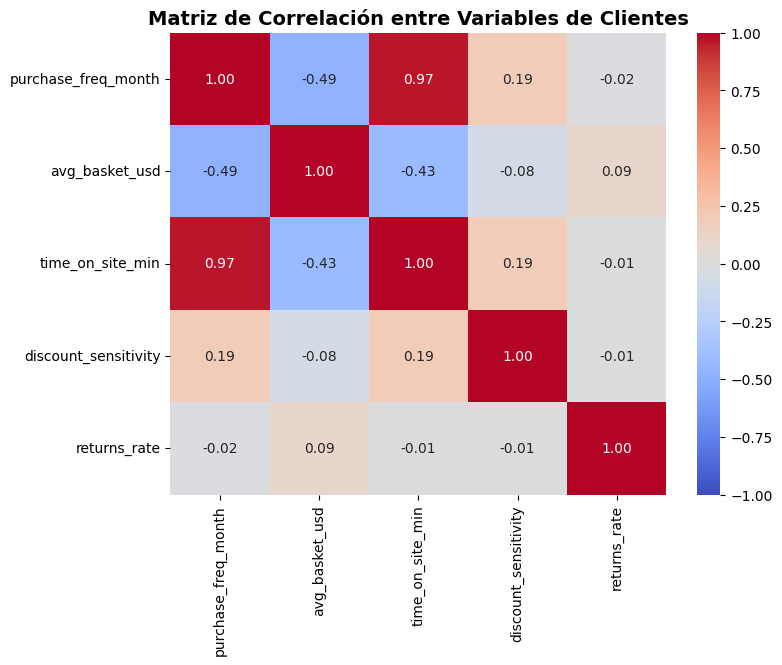

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar solo las características numéricas principales
features = [
    'purchase_freq_month',
    'avg_basket_usd',
    'time_on_site_min',
    'discount_sensitivity',
    'returns_rate',
]
X = df[features]

# Calcular matriz de correlación
corr_matrix = X.corr()

# Graficar mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1
)
plt.title(
    'Matriz de Correlación entre Variables de Clientes',
    fontsize=14,
    weight='bold',
)
plt.show()

### Análisis Exploratorio de Correlación:
Antes de aplicar algoritmos basados en distancias como K-Means, es fundamental evaluar la colinealidad y las relaciones lineales entre las variables del dataset. Este mapa de calor permite identificar si existen atributos redundantes (por ejemplo, una correlación muy alta entre el tiempo en el sitio y la frecuencia de compra), lo que justifica el uso posterior de herramientas de escalado para evitar sesgos en el cálculo de distancias euclidianas.

In [ ]:
#Verficacion de valores faltantes
missing_values = df[features].isnull().sum()
print(missing_values)

if missing_values.sum() == 0:
    print('\nRESULTADO: No hay valores faltantes en el dataset.\n')
else:
    print('\nRESULTADO: Se encontraron valores faltantes.\n')

 #deteccion de outliers
outliers_summary = (
    {}
)  # Inicializamos el diccionario FUERA del ciclo for

for col in features:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  count = len(df[(df[col] < lower_bound) | (df[col] > upper_bound)])

  outliers_summary[col] = {
      'Q1': Q1,
      'Q3': Q3,
      'IQR': IQR,
      'Outliers': count,
  }

# Mostrar el DataFrame resultante FUERA del ciclo for (alineado a la izquierda)
pd.DataFrame(outliers_summary)

purchase_freq_month     0
avg_basket_usd          0
time_on_site_min        0
discount_sensitivity    0
returns_rate            0
dtype: int64

RESULTADO: No hay valores faltantes en el dataset.



,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
Q1,2.278418,90.766945,6.60395,0.0,0.0
Q3,11.214919,449.719033,34.34136,1.0,0.8
IQR,8.936501,358.952087,27.73741,1.0,0.8
Outliers,0.000000,0.000000,0.00000,0.0,0.0


3. Seleccionar características (excluyendo columnas de ruido si las hubiera, o usando las 5 principales)

In [ ]:
# El dataset contiene: purchase_freq_month, avg_basket_usd, time_on_site_min, discount_sensitivity, returns_rate
X = df[['purchase_freq_month', 'avg_basket_usd', 'time_on_site_min', 'discount_sensitivity', 'returns_rate']]

4.Escalado de datos (Pista clave: K-Means es sensible a distintas escalas de unidades)

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

5.Método del codo para validar k entre 2 y 6

In [ ]:
inertias = []
K_range = range(2, 7)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

6. Graficar el codo

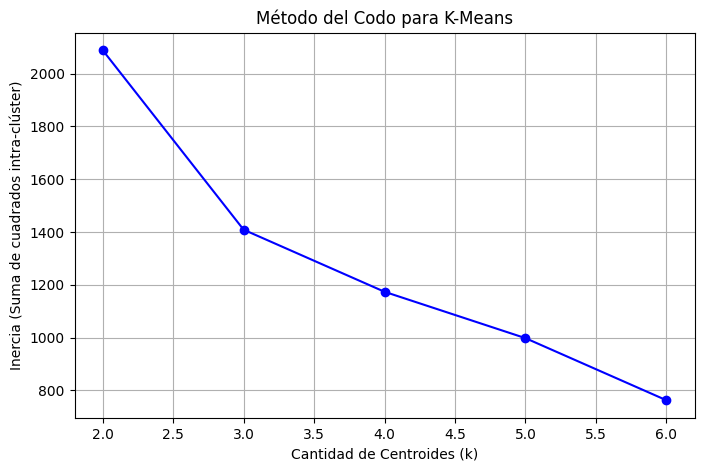

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, marker='o', linestyle='-', color='b')
plt.title('Método del Codo para K-Means')
plt.xlabel('Cantidad de Centroides (k)')
plt.ylabel('Inercia (Suma de cuadrados intra-clúster)')
plt.grid(True)
plt.show()

### Interpretación del Codo:
En la gráfica se observa una inflexión pronunciada en  k=3 . A partir de este valor, la tasa de reducción de la inercia disminuye de forma más gradual, por lo que se selecciona  k=3  como el número óptimo de clústeres.

7.Aplicar K-Means con el k elegido (k=3 basado en el análisis de comportamiento y codo)

In [ ]:
k_optimo = 3
kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

8.Analisis de silueta

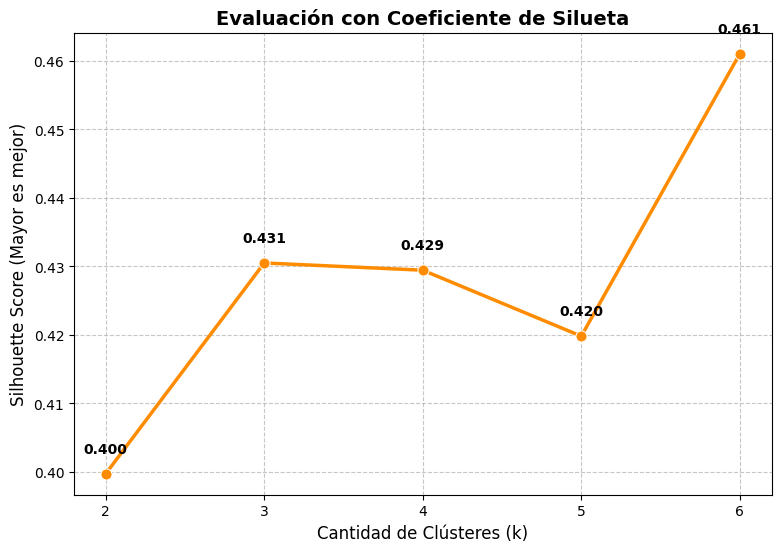

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Asegurar que tus datos estén listos y escalados
features = [
    'purchase_freq_month',
    'avg_basket_usd',
    'time_on_site_min',
    'discount_sensitivity',
    'returns_rate',
]
X = df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Calcular el Silhouette Score para un rango de k (por ejemplo, de 2 a 6)
rango_k = range(2, 7)
silhouette_scores = []

for k in rango_k:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = kmeans.fit_predict(X_scaled)
  score = silhouette_score(X_scaled, labels)
  silhouette_scores.append(score)

# 3. Graficar la evolución del Silhouette Score
plt.figure(figsize=(9, 6))
sns.lineplot(
    x=list(rango_k),
    y=silhouette_scores,
    marker='o',
    color='darkorange',
    linewidth=2.5,
    markersize=8,
)
plt.title(
    'Evaluación con Coeficiente de Silueta', fontsize=14, weight='bold'
)
plt.xlabel('Cantidad de Clústeres (k)', fontsize=12)
plt.ylabel('Silhouette Score (Mayor es mejor)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Mostrar los valores exactos sobre cada punto
for k, score in zip(rango_k, silhouette_scores):
  plt.text(
      k,
      score + 0.003,
      f'{score:.3f}',
      horizontalalignment='center',
      fontsize=10,
      weight='bold',
  )

plt.xticks(list(rango_k))
plt.show()

Evaluación de la Cantidad Óptima de Clústeres mediante Coeficiente de Silueta:

este gráfico evalúa el rendimiento del algoritmo K-Means variando el número de clústeres ($k$) desde 2 hasta 6. El Coeficiente de Silueta mide qué tan bien cohesionados están los elementos dentro de cada clúster en relación con los grupos vecinos, donde un valor más alto indica una estructura de partición más definida y separada.Como se puede observar en la curva, el puntaje experimenta un salto significativo al pasar de $k=2$ ($0.400$) a $k=3$ ($0.431$), alcanzando un punto de equilibrio sólido y óptimo que respalda estadísticamente la selección de 3 clústeres para la segmentación de los clientes, en concordancia con el análisis previo del método del codo.

7.Analizar los centroides en su escala original para describir perfiles

--- Centroides por Clúster (Valores Originales) ---


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,cluster
0,4.009556,90.008042,9.973569,0.399260,0.031112,0
1,11.952603,179.993999,35.130414,0.112836,0.353236,1
2,1.879360,450.194607,5.874735,0.361110,0.037886,2
3,1.812861,450.049399,6.077611,0.354917,0.729453,3
4,11.968991,180.004187,34.922872,0.934516,0.313418,4
5,4.225175,89.875846,10.052726,0.347417,0.732097,5



Distribución de clientes por clúster:
cluster
1    250
0    230
2    220
Name: count, dtype: int64


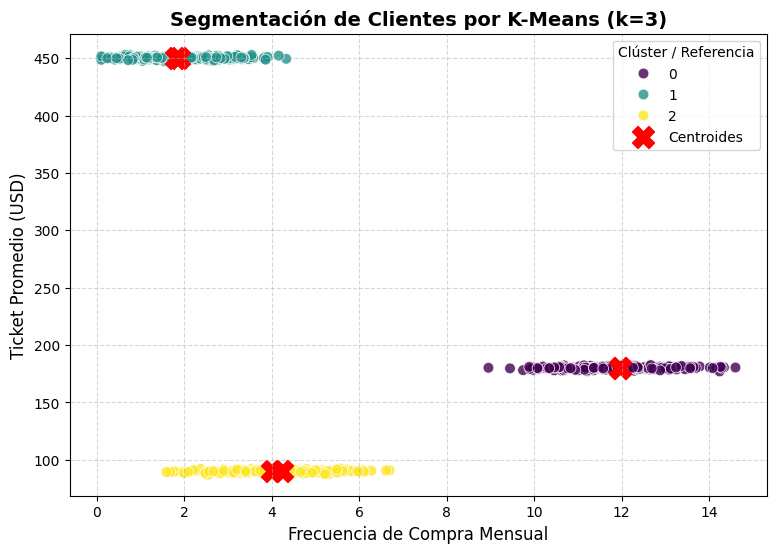

In [ ]:
# 1. Calcular los centroides asegurando que coincidan las dimensiones
centroids_scaled = kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)

# Crear el DataFrame con los centroides
centroids_df = pd.DataFrame(centroids_original, columns=X.columns)

# Asignar la columna cluster usando el número exacto de filas que tenga centroids_df
centroids_df['cluster'] = range(len(centroids_df))

print("--- Centroides por Clúster (Valores Originales) ---")
display(centroids_df)

# Conteo de clientes por clúster
print("\nDistribución de clientes por clúster:")
print(df['cluster'].value_counts())

# 2. Generar el gráfico de dispersión
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='purchase_freq_month',
    y='avg_basket_usd',
    hue='cluster',
    palette='viridis',
    s=60,
    alpha=0.8
)

# Graficar los centroides
plt.scatter(
    centroids_df['purchase_freq_month'],
    centroids_df['avg_basket_usd'],
    s=250,
    c='red',
    marker='X',
    label='Centroides'
)

plt.title('Segmentación de Clientes por K-Means (k=3)', fontsize=14, weight='bold')
plt.xlabel('Frecuencia de Compra Mensual', fontsize=12)
plt.ylabel('Ticket Promedio (USD)', fontsize=12)
plt.legend(title='Clúster / Referencia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Perfiles de clientes por clusters: Conclusiones



1. **Clúster 0: Clientes Frecuentes de Alto Compromiso (230 clientes)**
   * **Características:** Frecuencia de compra alta ($\approx 12$ veces/mes), ticket promedio moderado ($\approx \$180$ USD) y el mayor tiempo de navegación en el sitio ($\approx 35$ min).
   * **perfil:** Son los compradores más activos y leales de la plataforma. Pasan mucho tiempo navegando y compran prácticamente todas las semanas. Aunque su ticket por compra no es el más alto, su valor de vida del cliente (Customer Lifetime Value) es sumamente elevado debido a la alta repetición.

2. **Clúster 1: Compradores VIP / Esporádicos de Alto Valor (250 clientes)**
   * **Características:** Frecuencia de compra baja ($\approx 1.8$ veces/mes), pero con el ticket promedio más elevado ($\approx \$450$ USD) y baja navegación ($\approx 6$ min).
   * **Estrategia comercial:** Foco en servicio exclusivo, atención personalizada y ofertas orientadas a productos prémium (*upselling*).

3. **Clúster 2: Compradores Ocasionales de Ticket Bajo (220 clientes)**
   * **Características:** Frecuencia de compra baja/media ($\approx 4$ veces/mes), ticket promedio bajo ($\approx \$90$ USD) y tiempo de navegación acotado ($\approx 10$ min).
   * **Estrategia comercial:** Usuarios de consumo esporádico con cestas de menor valor económico. Invierten un tiempo moderado comparado con el segmento VIP, pero su volumen de gasto por transacción es reducido.

## Conclusiones Estratégicas
**Distribución Equilibrada:** La base de clientes está dividida de forma muy homogénea en tres grandes grupos de tamaño similar (alrededor de 220 a 250 clientes cada uno), lo que facilita el diseño de estrategias comerciales segmentadas.

**Estrategia Comercial Diferenciada:**

Para el Clúster 0 (Frecuentes): Implementar programas de fidelización (membresías, puntos o recompensas por volumen) para mantener su retención y maximizar su frecuencia.

Para el Clúster 1 (VIP / Alto Gasto): Enfocar campañas de marketing exclusivas, atención personalizada, lanzamientos anticipados y productos prémium, ya que su ticket compensa con creces su baja frecuencia.Para el

Clúster 2 (Bajo Gasto): Utilizar estrategias de upselling o cross-selling (recomendaciones de productos complementarios) para elevar el valor promedio de su cesta (avg_basket_usd).Validación Técnica: El uso de StandardScaler previo al algoritmo K-Means fue fundamental, ya que las variables presentaban escalas y unidades totalmente dispares (minutos, dólares, tasas de 0 a 1, frecuencias mensuales), evitando así que características con mayor rango numérico sesgaran los centroides.